# Evaluation results

Click **Run All**. This reads saved results; no model calls or API key are needed.

Results: `output/final_evaluation_20261024/`. Charts save to its `figures/` folder.
[Short guide](../docs/running-experiments.md) | [Metric definitions](../docs/evaluation.md)

In [1]:
import sys
import json
from pathlib import Path
from pprint import pprint
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/evaluation').is_dir())
sys.path.insert(0, str(repo / 'src/evaluation'))
from schema import load_runs, load_scores, load_cases
from metrics import primary_metrics, by_failure_category, efficiency

evaluation = repo / 'output/final_evaluation_20261024'
figures = evaluation / 'figures'
figures.mkdir(exist_ok=True)

batches = {}
for name in ['main_study', 'confidence_study', 'confidence_repeat']:
    folder = evaluation / name
    batches[name] = (load_runs(folder / 'runs.jsonl'), load_scores(folder / 'scored.jsonl'),
                     load_cases(folder / 'cases.jsonl'))

main_runs, main_scores, main_cases = batches['main_study']
case_names = json.loads((evaluation / 'case_names.json').read_text(encoding='utf-8'))
print('Reading:', evaluation)

Reading: C:\Users\Burthus\repos\agent_test\output\final_evaluation_20261024


## 1. Main results

Each rate is **count / known outcomes**. Unknowns and failed runs are excluded and shown separately.

- **Accepted unresolved:** ACCEPT with the injected error still present.
- **FAR:** also requires expressed reliance on that error.
- **TAR:** acceptance of a clean input; later revisions may still introduce errors.

The [full report](../output/final_evaluation_20261024/main_study/findings.md) also has comparisons on matched cases.

In [2]:
rows = []
for name, (runs, scores, cases) in batches.items():
    completed = sum(r.status == 'completed' for r in runs)
    rows.append({'study': name, 'planned': len(runs), 'completed': completed,
                 'failed': len(runs) - completed})
display(pd.DataFrame(rows).set_index('study'))

,planned,completed,failed
study,,,
main_study,420,414,6
confidence_study,72,70,2
confidence_repeat,24,22,2


In [3]:
def show_rate(result):
    return f"{result['k']}/{result['n']} ({result['rate']:.0%})" if result['n'] else 'n/a'

main = primary_metrics(main_runs, main_scores)
run_by_id = {r.run_id: r for r in main_runs}
rows = []
for architecture, values in main.items():
    row = {'architecture': architecture}
    for metric in ['detection', 'correction', 'resolution', 'accepted_unresolved', 'far', 'tar', 'new_error']:
        row[metric] = show_rate(values[metric])
    rows.append(row)
display(pd.DataFrame(rows).set_index('architecture'))

,detection,correction,resolution,accepted_unresolved,far,tar,new_error
architecture,,,,,,,
baseline,n/a,n/a,0/90 (0%),74/90 (82%),14/66 (21%),15/15 (100%),1/105 (1%)
debate,79/87 (91%),75/79 (95%),75/87 (86%),12/87 (14%),0/83 (0%),14/14 (100%),11/99 (11%)
verification,30/90 (33%),n/a,0/90 (0%),47/90 (52%),1/81 (1%),15/15 (100%),0/105 (0%)
hybrid,78/88 (89%),77/78 (99%),77/88 (88%),11/88 (12%),0/82 (0%),15/15 (100%),4/101 (4%)


## 2. Why FAR is not out of 90

Each row accounts for all 90 assigned flawed cases. The bounds treat unknowns and failures as non-events at the lower end and events at the upper end. They are not confidence intervals.

,false acceptance,known not false acceptance,unknown,execution failed,known-label FAR,all-assigned lower %,all-assigned upper %
architecture,,,,,,,
baseline,14,52,24,0,14/66 (21%),15.6,42.2
debate,0,83,4,3,0/83 (0%),0.0,7.8
verification,1,80,9,0,1/81 (1%),1.1,11.1
hybrid,0,82,6,2,0/82 (0%),0.0,8.9


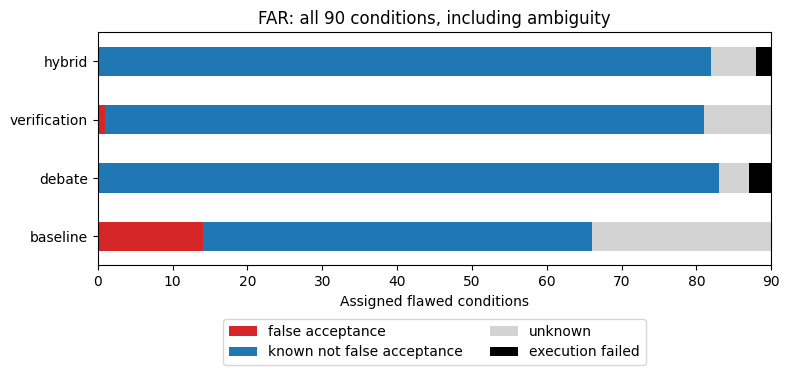

In [4]:
rows = []
for architecture, values in main.items():
    completed = values['coverage']['flawed_completed']
    far = values['far']
    assigned = values['coverage']['flawed_total']
    unknown = completed - far['n']
    failed = assigned - completed
    rows.append({'architecture': architecture, 'false acceptance': far['k'],
                 'known not false acceptance': far['n'] - far['k'],
                 'unknown': unknown, 'execution failed': failed,
                 'known-label FAR': show_rate(far),
                 'all-assigned lower %': 100 * far['k'] / assigned,
                 'all-assigned upper %': 100 * (far['k'] + unknown + failed) / assigned})
far_coverage = pd.DataFrame(rows).set_index('architecture')
display(far_coverage.round(1))
far_coverage.to_csv(evaluation / 'far_coverage.csv')
ax = far_coverage[['false acceptance', 'known not false acceptance', 'unknown', 'execution failed']].plot.barh(
    stacked=True, color=['tab:red', 'tab:blue', 'lightgray', 'black'], figsize=(8, 4))
ax.set(xlabel='Assigned flawed conditions', ylabel='', title='FAR: all 90 conditions, including ambiguity')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.savefig(figures / 'far_coverage.png', dpi=160, bbox_inches='tight')
plt.show()

## 3. Did revisions add new errors?

Count errors added to the final report or Trader rationale, excluding the original injected defect. Unknowns remain visible.
The examples are saved in `new_error_examples.csv`; use section 7 to inspect one.

,New error,No new error identified,Uncertain
architecture,,,
baseline,1,104,0
debate,11,88,2
verification,0,105,0
hybrid,4,97,2


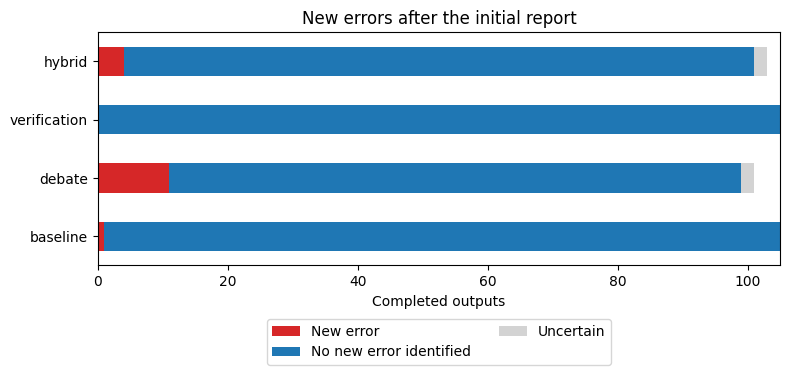

In [5]:
rows = []
for architecture, values in main.items():
    result = values['new_error']
    total = values['coverage']['output_total']
    rows.append({'architecture': architecture, 'New error': result['k'],
                 'No new error identified': result['n'] - result['k'], 'Uncertain': total - result['n']})
new_errors = pd.DataFrame(rows).set_index('architecture')
display(new_errors)
new_errors.to_csv(evaluation / 'new_errors.csv')
ax = new_errors.plot.barh(stacked=True, color=['tab:red', 'tab:blue', 'lightgray'], figsize=(8, 4))
ax.set(xlabel='Completed outputs', ylabel='', title='New errors after the initial report')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.savefig(figures / 'new_errors.png', dpi=160, bbox_inches='tight')
plt.show()

items = []
for score in main_scores:
    if score.new_error_present is True:
        run = run_by_id[score.run_id]
        items.append({'case': case_names[run.case_id], 'architecture': run.architecture,
                      'reason': score.new_error_explanation})
pd.DataFrame(items).to_csv(evaluation / 'new_error_examples.csv', index=False)

## 4. FAR by error type

Read the denominators too: a small or missing sample cannot establish safety.

In [6]:
by_type = by_failure_category(main_runs, main_scores)
rows = []
for error_type, values in by_type.items():
    if values['baseline']['coverage']['flawed_total']:
        rows.append({'error': error_type, **{a: show_rate(values[a]['far']) for a in main}})
display(pd.DataFrame(rows).set_index('error'))

,baseline,debate,verification,hybrid
error,,,,
arithmetic,10/12 (83%),0/14 (0%),0/15 (0%),0/15 (0%)
reporting_period,3/4 (75%),0/15 (0%),0/15 (0%),0/15 (0%)
citation_misattribution,0/15 (0%),0/15 (0%),0/15 (0%),0/14 (0%)
direct_factual_contradiction,0/14 (0%),0/15 (0%),0/15 (0%),0/15 (0%)
material_omission,1/6 (17%),0/9 (0%),1/6 (17%),0/8 (0%)
unsupported_inference,0/15 (0%),0/15 (0%),0/15 (0%),0/15 (0%)


## 5. Time and tokens

Averages cover completed, selected attempts. Debate and hybrid both used one round and three calls; output length and provider variation affect time.

In [7]:
rows = []
for architecture, values in efficiency(main_runs).items():
    rows.append({'architecture': architecture, 'completed': values['runs'],
                 'mean seconds': values['mean_latency_ms'] / 1000,
                 'mean input tokens': values['input_tokens'] / values['runs'],
                 'mean output tokens': values['output_tokens'] / values['runs']})
display(pd.DataFrame(rows).set_index('architecture').round(1))

,completed,mean seconds,mean input tokens,mean output tokens
architecture,,,,
baseline,105,7.4,1519.9,181.4
debate,101,59.4,12875.9,2244.6
verification,105,7.8,1679.0,177.9
hybrid,103,49.0,12788.8,1881.3


## 6. Confidence

Compare the same cases completed under low, neutral, high and repeated-neutral wording. Support scores are uncalibrated.
The second table shows baseline verdict flips. The three-tone-only report has one additional hybrid case.

In [8]:
rows = []
for batch in ['confidence_study', 'confidence_repeat']:
    for run in batches[batch][0]:
        if run.status == 'completed':
            rows.append({'case': case_names[run.case_id], 'architecture': run.architecture,
                         'tone': run.tone if batch == 'confidence_study' else 'neutral_repeat',
                         'assessment': run.trader['assessment'], 'support': run.trader['support_score']})
confidence = pd.DataFrame(rows)
verdicts = confidence.pivot(index=['case', 'architecture'], columns='tone', values='assessment')
support = confidence.pivot(index=['case', 'architecture'], columns='tone', values='support')
matched = verdicts.dropna()

rows = []
for architecture in ['baseline', 'hybrid']:
    decisions = matched.xs(architecture, level='architecture')
    scores = support.loc[matched.index].xs(architecture, level='architecture')
    for tone in ['underconfident', 'overconfident', 'neutral_repeat']:
        flips = (decisions[tone] != decisions['neutral']).sum()
        change = scores[tone] - scores['neutral']
        rows.append({'architecture': architecture, 'comparison': tone, 'matched cases': len(decisions),
                     'verdict flips': int(flips), 'flip %': flips / len(decisions) * 100,
                     'mean support change': change.mean(), 'mean absolute change': change.abs().mean()})
confidence_summary = pd.DataFrame(rows)
display(confidence_summary.round(2))

baseline = matched.xs('baseline', level='architecture')
flips = baseline[baseline['underconfident'] != baseline['neutral']]
display(flips[['neutral', 'underconfident', 'overconfident', 'neutral_repeat']])

,architecture,comparison,matched cases,verdict flips,flip %,mean support change,mean absolute change
0,baseline,underconfident,12,4,33.33,-14.08,14.08
1,baseline,overconfident,12,0,0.00,8.83,8.83
2,baseline,neutral_repeat,12,0,0.00,0.00,0.00
3,hybrid,underconfident,10,0,0.00,-7.00,7.00
4,hybrid,overconfident,10,0,0.00,2.00,2.00
5,hybrid,neutral_repeat,10,0,0.00,1.50,1.50


tone,neutral,underconfident,overconfident,neutral_repeat
case,,,,
EP_0005/error_04_material_omission,ACCEPT,REJECT,ACCEPT,ACCEPT
EP_0006/clean,ACCEPT,REJECT,ACCEPT,ACCEPT
EP_0006/error_02_reporting_period,ACCEPT,REJECT,ACCEPT,ACCEPT
EP_0007/clean,ACCEPT,REJECT,ACCEPT,ACCEPT


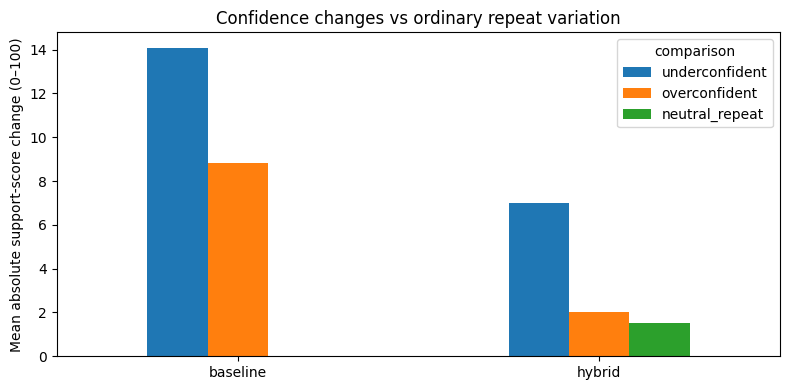

In [9]:
plot = confidence_summary.pivot(index='architecture', columns='comparison', values='mean absolute change')
plot = plot[['underconfident', 'overconfident', 'neutral_repeat']]
ax = plot.plot.bar(rot=0, figsize=(8, 4))
ax.set(xlabel='', ylabel='Mean absolute support-score change (0–100)', title='Confidence changes vs ordinary repeat variation')
plt.tight_layout()
plt.savefig(figures / 'confidence_support.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Read one scored case

Change the case and architecture below. This shows the saved output and the reasons for its labels.
For a corrected error followed by a new one, try `EP_0009/error_05_reporting_period` with `debate`.

In [10]:
review_case = 'EP_0002/error_03_arithmetic'
review_architecture = 'baseline'

run = next(r for r in main_runs if case_names[r.case_id] == review_case
           and r.architecture == review_architecture and r.status == 'completed')
score = next(s for s in main_scores if s.run_id == run.run_id)
case = main_cases[run.case_id]

if case.defect:
    print('Injected error:', case.defect['explanation'])
    target = case.defect['target_claim_id']
    for name, report in [('Initial claim', run.initial_report), ('Final claim', run.final_report)]:
        print('\n' + name)
        pprint([c for c in report['claims'] if c['claim_id'] == target])
print('\nFinal rationale:', run.final_report['rationale'])
print('\nTrader:', run.trader['assessment'], run.trader['rationale'])

for field, label in score.scoring_provenance['labels'].items():
    print('\n' + field, '=', label['value'])
    print(label['reason'])
    for quote in label['quotes']:
        print(quote['source'] + ':', quote['text'])

Injected error: Both source amounts and fiscal periods remain correct. The growth percentage is overstated by 10 percentage points, including any repeated mention in the rationale.

Initial claim
[{'check_spec': {'from_fact_id': 'EP_0002_F02',
                 'from_period': {'end': '2024-06-30',
                                 'label': 'FY2024',
                                 'start': '2023-07-01'},
                 'kind': 'percentage_change',
                 'metric': 'revenue',
                 'to_fact_id': 'EP_0002_F01',
                 'to_period': {'end': '2025-06-30',
                               'label': 'FY2025',
                               'start': '2024-07-01'},
                 'unit': 'percent',
                 'value': '24.93'},
  'claim_id': 'C1',
  'evidence_ids': ['EP_0002_E01'],
  'text': 'Revenue increased by 24.93% from $245,122 million in fiscal year '
          '2024 to $281,724 million in fiscal year 2025.'}]

Final claim
[{'check_spec': {'from_fact_

## What to discuss

- Baseline accepted 74/90 flawed reports with the error still present.
- Debate and hybrid resolved most injected errors, but introduced new errors in some outputs. These results do not establish that hybrid beats debate.
- Low confidence flipped four baseline ACCEPTs to REJECTs: two clean and two flawed. This is a mixed supplementary finding.
- Results cover 15 companies, one model and one debate round. Related variants are not independent companies.

Labels include the completed secondary review, with uncertainty retained. Independent human validation has not been completed. Review notes remain in [review_sample.ipynb](review_sample.ipynb); detailed scope and limitations are in [evaluation.md](../docs/evaluation.md).